<a href="https://colab.research.google.com/github/sanabahadur179529h-arch/HAR-Walking-Recognition/blob/main/Human_activity_walking_dr_ephin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()
zip_name = list(uploaded.keys())[0]
print("Uploaded:", zip_name)


Saving Acceleration with g 2026-11-07 09-48-33.zip to Acceleration with g 2026-11-07 09-48-33.zip
Uploaded: Acceleration with g 2026-11-07 09-48-33.zip


In [6]:
import zipfile
import os

zip_file = "Acceleration with g 2026-11-07 09-48-33.zip"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("walking_data")

print("ZIP file extracted successfully!")

print("Files inside the ZIP:")
for file in os.listdir("walking_data"):
    print(file)

ZIP file extracted successfully!
Files inside the ZIP:
meta
Raw Data.csv


In [ ]:
LABEL = "walking"   # change to your real activity

full = df.copy()
full["Time (s)"] = full["Time (s)"] - full["Time (s)"].iloc[0]
full["label"] = LABEL

out_name = f"{LABEL}_dataset_2026-11-07.csv"
full.to_csv(out_name, index=False)
print("Saved:", out_name, "| Rows:", len(full))
print(full.head())

Saved: walking_dataset_2026-11-07.csv | Rows: 12013
   Time (s)  Acceleration x (m/s^2)  Acceleration y (m/s^2)  \
0  0.000000               -0.315993                7.038064   
1  0.009989               -0.288899                7.064260   
2  0.019978               -0.278122                7.076085   
3  0.029967               -0.288899                7.122040   
4  0.039956               -0.311652                7.129225   

   Acceleration z (m/s^2)  Absolute acceleration (m/s^2)    label  
0                6.850055                       9.826365  walking  
1                6.944659                       9.910374  walking  
2                7.028634                       9.977476  walking  
3                7.127578                      10.080143  walking  
4                7.223678                      10.154039  walking  


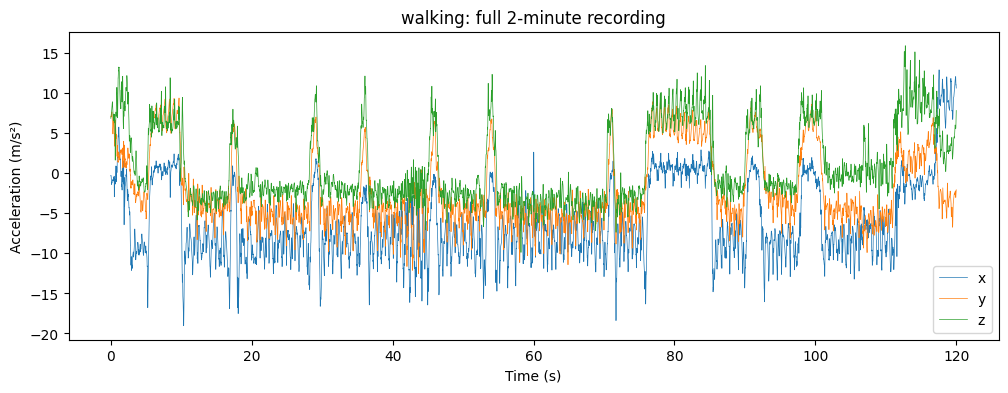

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(full["Time (s)"], full["Acceleration x (m/s^2)"], label="x", linewidth=0.5)
plt.plot(full["Time (s)"], full["Acceleration y (m/s^2)"], label="y", linewidth=0.5)
plt.plot(full["Time (s)"], full["Acceleration z (m/s^2)"], label="z", linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title(f"{LABEL}: full 2-minute recording")
plt.legend()
plt.savefig(f"{LABEL}_full_2026-11-07.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files
files.download(out_name)
files.download(f"{LABEL}_full_2026-11-07.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pandas as pd
from google.colab import files
import io

# Upload raw walking sensor data
uploaded = files.upload()

# Read the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the dataset
print("PRIVATE WALKING DATASET")
print("First 5 rows:")
display(df.head())

# Show columns and data types
print("Dataset information:")
df.info()

# Check dataset size
print("Dataset shape:", df.shape)

Saving Raw_Data[1].csv to Raw_Data[1].csv
PRIVATE WALKING DATASET
First 5 rows:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.004125,-0.315993,7.038064,6.850055,9.826365
1,0.014114,-0.288899,7.064260,6.944659,9.910374
2,0.024103,-0.278122,7.076085,7.028634,9.977476
3,0.034092,-0.288899,7.122040,7.127578,10.080143
4,0.044081,-0.311652,7.129225,7.223678,10.154039


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12013 entries, 0 to 12012
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Time (s)                       12013 non-null  float64
 1   Acceleration x (m/s^2)         12013 non-null  float64
 2   Acceleration y (m/s^2)         12013 non-null  float64
 3   Acceleration z (m/s^2)         12013 non-null  float64
 4   Absolute acceleration (m/s^2)  12013 non-null  float64
dtypes: float64(5)
memory usage: 469.4 KB
Dataset shape: (12013, 5)


In [3]:
# STEP 4: DATA QUALITY CHECK AND CLEANING

# Make a copy of the original dataset
clean_df = df.copy()

# Check missing values
print("Missing values:")
print(clean_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Sort data by time
clean_df = clean_df.sort_values("Time (s)")

# Check time range
print("\nRecording starts at:", clean_df["Time (s)"].min(), "seconds")
print("Recording ends at:", clean_df["Time (s)"].max(), "seconds")

# Check acceleration statistics
print("\nAcceleration summary:")
display(clean_df.describe())

print("\nCleaned dataset shape:", clean_df.shape)

Missing values:
Time (s)                         0
Acceleration x (m/s^2)           0
Acceleration y (m/s^2)           0
Acceleration z (m/s^2)           0
Absolute acceleration (m/s^2)    0
dtype: int64

Duplicate rows:
0

Recording starts at: 0.004125291714 seconds
Recording ends at: 119.9997553 seconds

Acceleration summary:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
count,12013.000000,12013.000000,12013.000000,12013.000000,12013.000000
mean,59.999648,-5.972292,-1.983719,0.928276,10.138832
std,34.644115,4.885405,4.567243,4.705055,2.128012
min,0.004125,-19.034118,-12.524156,-9.879605,1.291970
25%,30.000365,-9.386531,-5.154681,-2.620900,8.665310
50%,59.998348,-7.306756,-3.789071,-1.207389,9.931092
75%,89.998388,-1.832639,1.581761,5.658683,11.415883
max,119.999755,12.901970,9.552984,15.915653,21.654106



Cleaned dataset shape: (12013, 5)


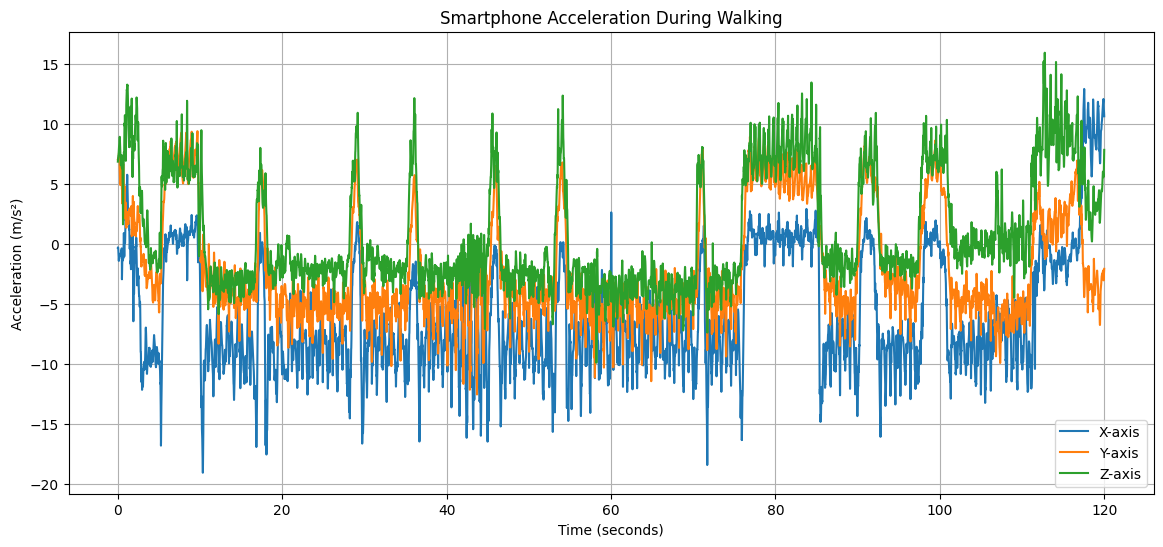

In [4]:
import matplotlib.pyplot as plt

# Plot acceleration on all three axes
plt.figure(figsize=(14, 6))

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration x (m/s^2)"],
         label="X-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration y (m/s^2)"],
         label="Y-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration z (m/s^2)"],
         label="Z-axis")

plt.title("Smartphone Acceleration During Walking")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True)
plt.show()